## RK4 Lorenz synchronisation
Run the RK4 definitions below first. Test a few coupling strengths c to find the synchronisation interval, then repeatedly halve that interval. The final cells produce two figures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0


def lorenz(X):
    x, y, z = X
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return np.array([dx, dy, dz])


def coupled_lorenz(U, c):
    X1 = U[:3]
    X2 = U[3:]
    dX1 = lorenz(X1) + c * (X2 - X1)
    dX2 = lorenz(X2) + c * (X1 - X2)
    return np.concatenate([dX1, dX2])


def rk4_step(U, h, c):
    k1 = coupled_lorenz(U, c)
    k2 = coupled_lorenz(U + h / 2 * k1, c)
    k3 = coupled_lorenz(U + h / 2 * k2, c)
    k4 = coupled_lorenz(U + h * k3, c)
    return U + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


In [2]:
# Time settings and initial conditions
t_end = 1000.0
h = 0.02
n_steps = int(t_end / h)
t = np.linspace(0.0, t_end, n_steps + 1)
start_step = int(800.0 / h)

X1_0 = [1.0, 1.0, 1.0]
X2_0 = [1.01, 1.0, 1.0]
sync_tolerance = 1e-5


def simulate(c, save=False):
    # Keep the whole trajectory only when a figure needs it.
    U = np.array(X1_0 + X2_0, dtype=float)
    history = np.empty((n_steps + 1, 6)) if save else None
    if save:
        history[0] = U

    max_error = 0.0
    for n in range(n_steps):
        U = rk4_step(U, h, c)
        if save:
            history[n + 1] = U
        if n + 1 >= start_step:
            error = np.linalg.norm(U[:3] - U[3:])
            max_error = max(max_error, error)

    return max_error, history


# First find a rough interval using only a few values of c.
results = {}
previous_c = None
for c in np.arange(0.0, 1.01, 0.2):
    c = round(float(c), 5)
    results[c], _ = simulate(c)
    print(f"c = {c:.5f}, maximum late-time error = {results[c]:.3e}")

    if results[c] < sync_tolerance:
        if previous_c is None:
            raise RuntimeError("The first tested c is already synchronised.")
        low, high = previous_c, c
        break
    previous_c = c
else:
    raise RuntimeError("No synchronisation found for c up to 1.")


# Halve the interval until its width is at most 0.01.
while high - low > 0.01:
    middle = round((low + high) / 2, 5)
    results[middle], _ = simulate(middle)
    print(f"c = {middle:.5f}, maximum late-time error = {results[middle]:.3e}")

    if results[middle] < sync_tolerance:
        high = middle
    else:
        low = middle

print(f"Estimated transition: {low:.5f} < c_crit <= {high:.5f}")
print(f"Full simulations used: {len(results)}")


c = 0.00000, maximum late-time error = 5.440e+01


c = 0.20000, maximum late-time error = 5.376e+01


c = 0.40000, maximum late-time error = 5.076e+01


c = 0.60000, maximum late-time error = 0.000e+00


c = 0.50000, maximum late-time error = 0.000e+00


c = 0.45000, maximum late-time error = 1.439e-02


c = 0.47500, maximum late-time error = 0.000e+00


c = 0.46250, maximum late-time error = 0.000e+00


c = 0.45625, maximum late-time error = 7.598e-09
Estimated transition: 0.45000 < c_crit <= 0.45625
Full simulations used: 9


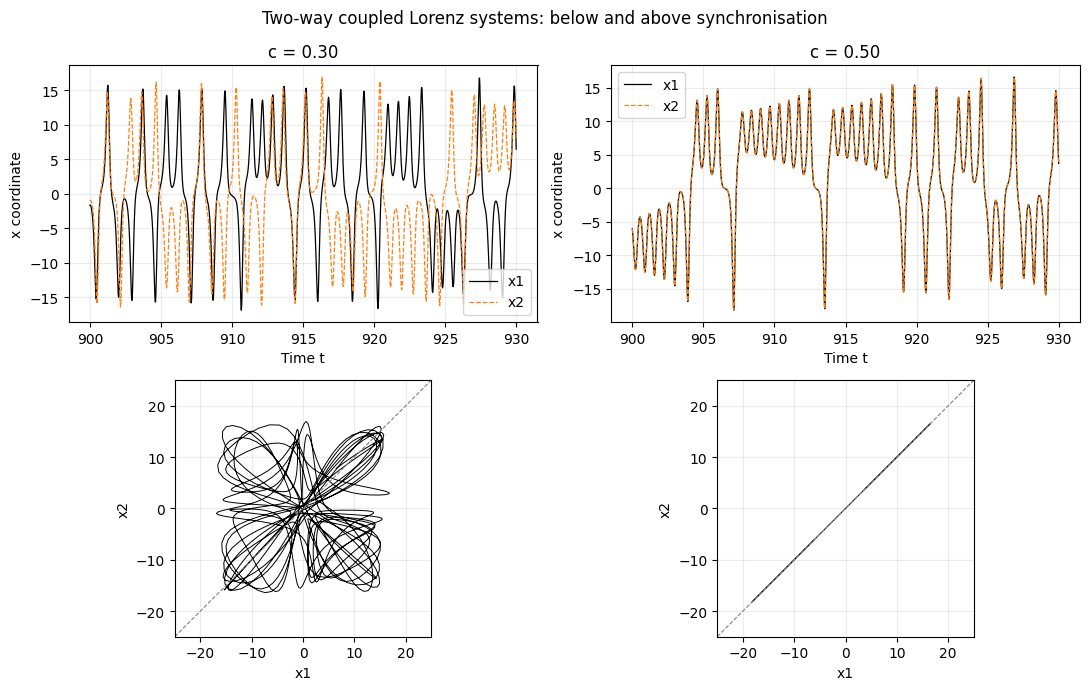

In [3]:
# Compare a clearly unsynchronised run with a synchronised run.
c_below = 0.30
c_above = 0.50
_, U_below = simulate(c_below, save=True)
_, U_above = simulate(c_above, save=True)

# Use the same late-time interval in all four panels.
window = (t >= 900) & (t <= 930)
fig, ax = plt.subplots(2, 2, figsize=(11, 7))

for column, (c, U) in enumerate([(c_below, U_below), (c_above, U_above)]):
    x1 = U[window, 0]
    x2 = U[window, 3]

    ax[0, column].plot(t[window], x1, label="x1", color="black", lw=0.9)
    ax[0, column].plot(t[window], x2, label="x2", color="tab:orange",
                       ls="--", lw=0.9)
    ax[0, column].set_title(f"c = {c:.2f}")
    ax[0, column].set_xlabel("Time t")
    ax[0, column].set_ylabel("x coordinate")
    ax[0, column].legend()
    ax[0, column].grid(alpha=0.25)

    ax[1, column].plot(x1, x2, color="black", lw=0.7)
    ax[1, column].plot([-25, 25], [-25, 25], color="gray", ls="--", lw=0.8)
    ax[1, column].set_xlim(-25, 25)
    ax[1, column].set_ylim(-25, 25)
    ax[1, column].set_aspect("equal", adjustable="box")
    ax[1, column].set_xlabel("x1")
    ax[1, column].set_ylabel("x2")
    ax[1, column].grid(alpha=0.25)

fig.suptitle("Two-way coupled Lorenz systems: below and above synchronisation")
fig.tight_layout()
fig.savefig("figure_914_rk4.png", dpi=180)
plt.show()


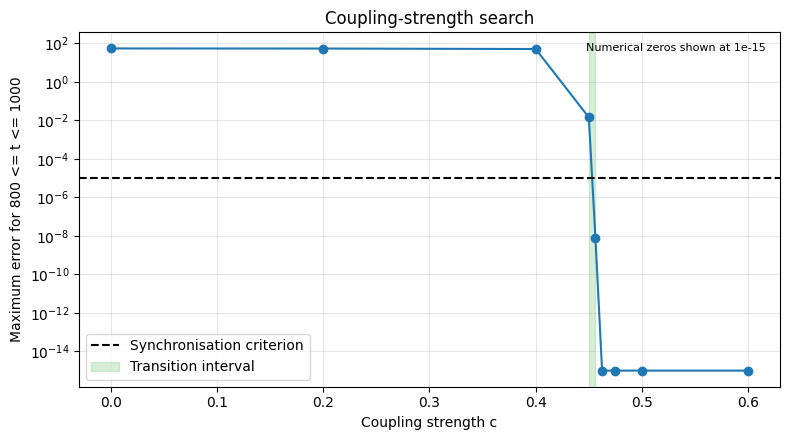

In [4]:
# Show how the late-time error changes over the tested coupling strengths.
c_tested = sorted(results)
max_errors = [results[c] for c in c_tested]
plot_errors = np.maximum(max_errors, 1e-15)  # Log scale cannot show exact zero.

plt.figure(figsize=(8, 4.5))
plt.semilogy(c_tested, plot_errors, "o-", color="tab:blue")
plt.axhline(sync_tolerance, color="black", ls="--",
            label="Synchronisation criterion")
plt.axvspan(low, high, color="tab:green", alpha=0.18,
            label="Transition interval")
plt.xlabel("Coupling strength c")
plt.ylabel("Maximum error for 800 <= t <= 1000")
plt.title("Coupling-strength search")
plt.grid(alpha=0.3)
plt.legend()
plt.text(0.98, 0.97, "Numerical zeros shown at 1e-15",
         transform=plt.gca().transAxes, ha="right", va="top", fontsize=8)
plt.tight_layout()
plt.savefig("error_vs_c_rk4.png", dpi=180)
plt.show()
